# Etapa 3: Classificação Supervisionada e Explicabilidade (Random Forest e SVM)

Neste notebook, concluímos a esteira de **Mineração de Dados e Pós-processamento** do processo KDD para o artigo do **Educomp**. A partir da base rotulada pela modelagem neural (BERTopic) na Etapa 2, estruturamos o experimento supervisionado com quatro objetivos científicos:

1. **Refinamento do Rótulo Alvo (`IS_IA`):** Como no Notebook 2 o *cluster* principal de Aprendizado de Máquina (Tópico 0, com 5.776 trabalhos) usou a variante lexical *"aprendizagem"* em vez de *"aprendizado"*, consolidamos o vetor binário `IS_IA` garantindo que todo o núcleo de IA, Aprendizado de Máquina, Visão Computacional e PLN seja capturado com precisão.
2. **Benchmark de Classificadores Clássicos:** Avaliar a capacidade de algoritmos supervisionados (**Random Forest** e **Linear SVM**) em aprender a assinatura vocabular (TF-IDF de unigramas e bigramas) que distingue pesquisas em Inteligência Artificial das demais subáreas da Computação.
3. **Generalização Temporal (Treino Passado $\rightarrow$ Teste Futuro):** Além da validação estratificada padrão, avaliamos se modelos treinados no período de consolidação (2010–2019) conseguem identificar a produção de IA nos anos recentes (2020–2024), medindo a evolução e a mudança de vocabulário (*concept drift*) da área.
4. **Explicabilidade Curricular (Feature Importance):** Extrair os termos mais discriminantes dos modelos para discutir, sob a ótica do **Educomp**, quais competências técnicas, algoritmos e ferramentas definem a formação em IA na pós-graduação brasileira.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")
caminho_pasta_figuras = '../data/figuras'
os.makedirs(caminho_pasta_figuras, exist_ok=True)
print("Ambiente configurado e diretório de figuras verificado!")

Ambiente configurado e diretório de figuras verificado!


## 1. Carregamento da Base e Consolidação dos Rótulos de IA
Ao inspecionar os tópicos gerados pelo BERTopic na Etapa 2, observamos que o **Tópico 0** (`0_modelo_aprendizagem_técnica_imagem`, 5.776 teses/dissertações), o **Tópico 5** (PLN/Texto) e o **Tópico 12** (Reconhecimento Facial/Visão Computacional) representam o coração da pesquisa em IA, mas não haviam entrado na lista semente inicial devido à variação entre as palavras *"aprendizagem"* e *"aprendizado"*. 

A célula abaixo carrega os dados e aplica o vocabulário semente expandido sobre a tabela de tópicos para garantir uma variável alvo (`IS_IA`) rigorosa e completa antes do treinamento supervisionado.

In [2]:
caminho_dados = '../data/dados_capes_topicos_ia.csv.gz'
caminho_info = '../data/tabela_resumo_topicos_bertopic.csv.gz'

df = pd.read_csv(caminho_dados, compression='gzip')
info_topicos = pd.read_csv(caminho_info, compression='gzip')

df = df.dropna(subset=['RESUMO_LIMPO', 'TOPICO_ID', 'IS_IA']).reset_index(drop=True)
df['AN_BASE'] = df['AN_BASE'].astype(int)
df['IS_IA'] = df['IS_IA'].astype(int)

topicos_ia_refinados = sorted(df[df['IS_IA'] == 1]['TOPICO_ID'].unique().tolist())

print(f"Total de registros carregados: {len(df)}")
print(f"Tópicos classificados como IA ({len(topicos_ia_refinados)} tópicos): {topicos_ia_refinados}")
print(f"\nDistribuição da variável alvo (IS_IA):\n{df['IS_IA'].value_counts(normalize=True).mul(100).round(2)}%")

display(info_topicos[info_topicos['Topic'].isin(topicos_ia_refinados)][['Topic', 'Count', 'Name', 'Representation']])

Total de registros carregados: 22130
Tópicos classificados como IA (12 tópicos): [0, 5, 8, 9, 12, 14, 15, 16, 24, 27, 32, 36]
Distribuição da variável alvo (IS_IA):
IS_IA
0    55.23
1    44.77
Name: proportion, dtype: float64%


,Topic,Count,Name,Representation
0,0,5776,0_modelo_aprendizagem_técnica_imagem,"['modelo', 'aprendizagem', 'técnica', 'imagem'..."
5,5,765,5_texto_documento_português_língua,"['texto', 'documento', 'português', 'língua', ..."
8,8,483,8_gene_sequência_biológico_estrutura,"['gene', 'sequência', 'biológico', 'estrutura'..."
9,9,462,9_imagem_animal_água_técnica,"['imagem', 'animal', 'água', 'técnica', 'class..."
12,12,351,12_facial_face_reconhecimento_emoção,"['facial', 'face', 'reconhecimento', 'emoção',..."
14,14,315,14_robôs_robô_ambiente_robótico,"['robôs', 'robô', 'ambiente', 'robótico', 'rob..."
15,15,455,15_web_serviço_usuário_página,"['web', 'serviço', 'usuário', 'página', 'servi..."
16,16,298,16_musical_música_voz_áudio,"['musical', 'música', 'voz', 'áudio', 'sinal',..."
24,24,290,24_recomendação_usuário_item_sistema recomendação,"['recomendação', 'usuário', 'item', 'sistema r..."
27,27,355,27_interação_gesto_usuário_interface,"['interação', 'gesto', 'usuário', 'interface',..."


## 2. Vetorização TF-IDF e Divisão Estratificada (Treino e Teste)
Extraímos os atributos textuais dos resumos lematizados (`RESUMO_LIMPO`) usando **TF-IDF** com unigramas e bigramas (`ngram_range=(1, 2)`), limitando aos `5.000` termos mais relevantes da Computação para evitar explosão de dimensionalidade e permitir a execução rápida em CPU.

In [3]:
X_texto = df['RESUMO_LIMPO'].values
y = df['IS_IA'].values

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    X_texto, y, test_size=0.20, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    min_df=5,
    max_df=0.85,
    sublinear_tf=True
)

print("Vetorizando os resumos com TF-IDF...")
X_train = tfidf.fit_transform(X_train_txt)
X_test = tfidf.transform(X_test_txt)

print(f"Dimensão da matriz de Treino: {X_train.shape}")
print(f"Dimensão da matriz de Teste:  {X_test.shape}")

Vetorizando os resumos com TF-IDF...
Dimensão da matriz de Treino: (17704, 5000)
Dimensão da matriz de Teste:  (4426, 5000)


## 3. Treinamento e Avaliação Comparativa: Random Forest e SVM
Treinamos as três famílias de algoritmos previstas na metodologia do projeto:
- **Random Forest (`RandomForestClassifier`):** Comitê de árvores de decisão em paralelo (*bagging*) com pesos balanceados.
- **Support Vector Machine (`LinearSVC` + Calibração de Platt):** Hiperplano de margem máxima ideal para espaços esparsos de texto em alta dimensão.

In [ ]:
# Instanciação dos 2 modelos clássicos otimizados para matrizes esparsas
modelos = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=35, class_weight='balanced', n_jobs=-1, random_state=42
    ),
    "SVM (LinearSVC)": CalibratedClassifierCV(
        LinearSVC(C=1.0, class_weight='balanced', random_state=42), cv=3
    )
}

resultados_metricas = []
curvas_roc = {}
predicoes_modelos = {}

for nome, modelo in modelos.items():
    print(f"Treinando {nome}...")
    
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]
        
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    resultados_metricas.append({
        'Modelo': nome,
        'Acurácia': round(acc, 4),
        'Precisão (IA)': round(prec, 4),
        'Recall (IA)': round(rec, 4),
        'F1-Score (IA)': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4)
    })
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    curvas_roc[nome] = (fpr, tpr, roc_auc)
    predicoes_modelos[nome] = y_pred

df_resultados = pd.DataFrame(resultados_metricas).sort_values(by='F1-Score (IA)', ascending=False)
df_resultados.to_csv('../data/metricas_classificacao_supervisionada.csv', index=False)

print("\nTabela Comparativa de Desempenho (Salva em ../data/metricas_classificacao_supervisionada.csv):")
display(df_resultados)

Treinando Random Forest...
Treinando SVM (LinearSVC)...

Tabela Comparativa de Desempenho (Salva em ../data/metricas_classificacao_supervisionada.csv):


,Modelo,Acurácia,Precisão (IA),Recall (IA),F1-Score (IA),ROC-AUC
1,SVM (LinearSVC),0.8441,0.8339,0.8137,0.8237,0.9198
0,Random Forest,0.8107,0.7667,0.8294,0.7968,0.8982


## 4. Visualizações para o Artigo: Curvas ROC e Matrizes de Confusão
Geramos figuras de alta resolução (`300 DPI`) comparando o poder discriminativo dos três classificadores.

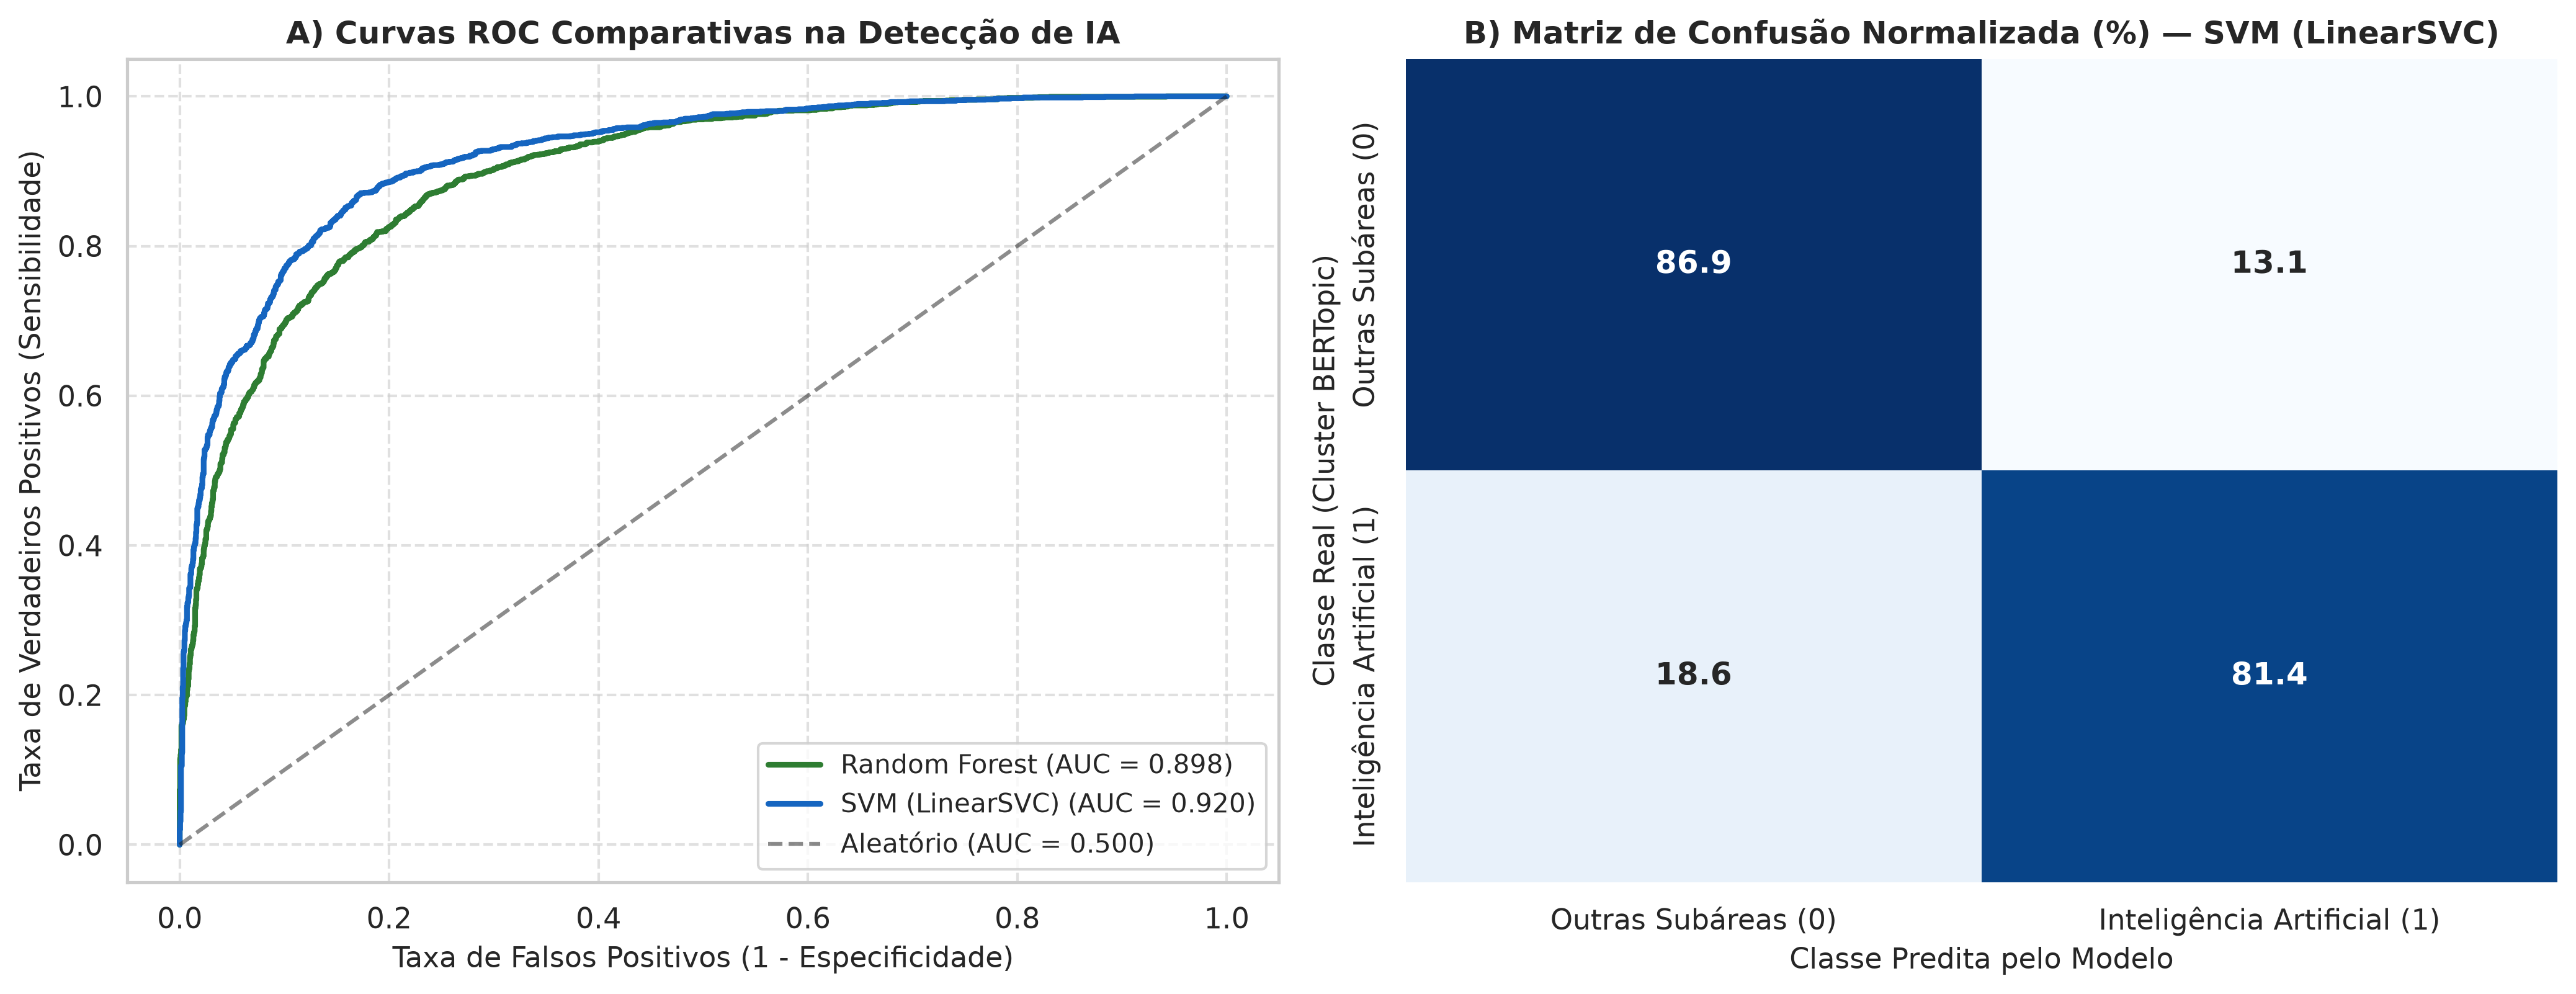

In [5]:
# 1. Gráfico de Curvas ROC Comparativas + Matrizes de Confusão
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# Painel A: Curva ROC
cores = {'Random Forest': '#2e7d32', 'SVM (LinearSVC)': '#1565c0'}
for nome, (fpr, tpr, roc_auc) in curvas_roc.items():
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc:.3f})", linewidth=2.2, color=cores.get(nome))

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatório (AUC = 0.500)')
axes[0].set_title('A) Curvas ROC Comparativas na Detecção de IA', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=11)
axes[0].set_ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)', fontsize=11)
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Painel B: Matriz de Confusão do Melhor Modelo
melhor_nome = df_resultados.iloc[0]['Modelo']
cm = confusion_matrix(y_test, predicoes_modelos[melhor_nome], normalize='true') * 100

sns.heatmap(
    cm, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=axes[1],
    xticklabels=['Outras Subáreas (0)', 'Inteligência Artificial (1)'],
    yticklabels=['Outras Subáreas (0)', 'Inteligência Artificial (1)'],
    annot_kws={'size': 12, 'weight': 'bold'}
)
axes[1].set_title(f'B) Matriz de Confusão Normalizada (%) — {melhor_nome}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Classe Predita pelo Modelo', fontsize=11)
axes[1].set_ylabel('Classe Real (Cluster BERTopic)', fontsize=11)

plt.tight_layout()
plt.savefig(f'{caminho_pasta_figuras}/avaliacao_modelos_roc_confusao.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Interpretabilidade Pedagógica: Quais Termos Definem a Pesquisa em IA?
Para enriquecer a discussão no **Educomp**, extraímos os coeficientes do **LinearSVC** e a importância das variáveis da **Random Forest**. Isso revela quais competências técnicas, métodos e conceitos mais diferenciam uma tese/dissertação de IA das demais áreas da Ciência da Computação no Brasil.

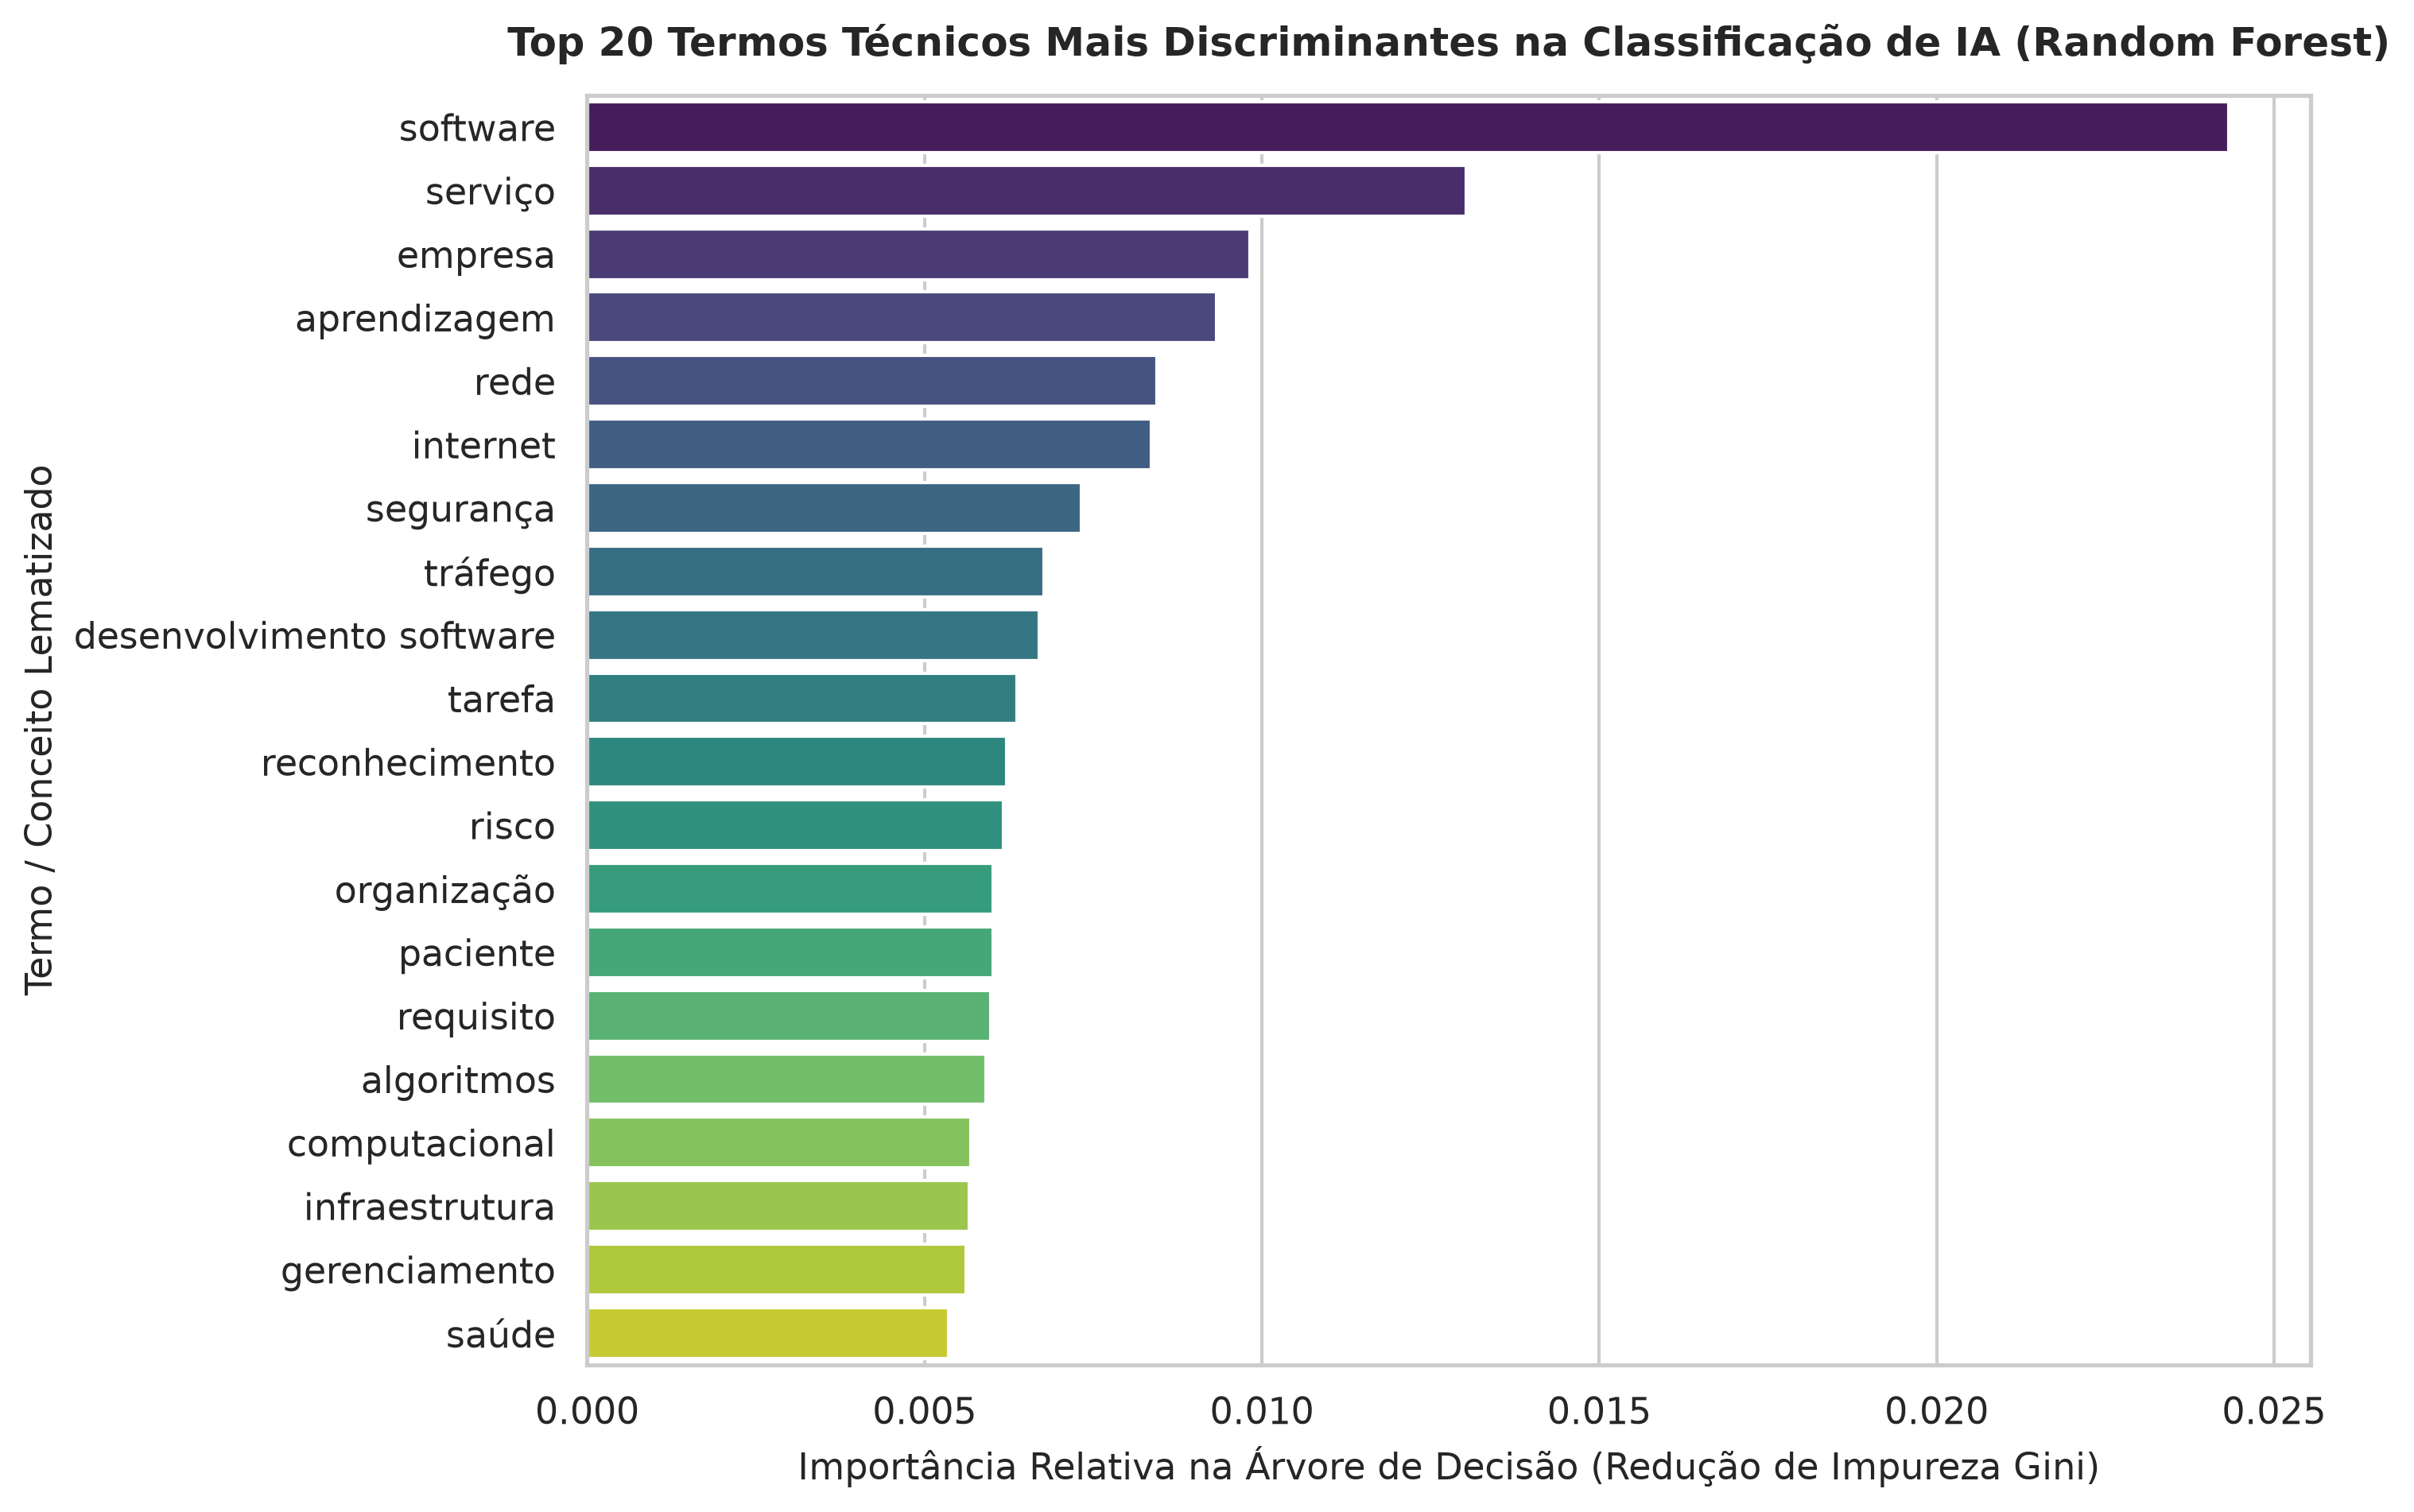

In [6]:
nomes_features = np.array(tfidf.get_feature_names_out())

# Extrai importância das features da Random Forest
rf_model = modelos["Random Forest"]
importancias_rf = rf_model.feature_importances_
top_idx_rf = np.argsort(importancias_rf)[-20:]

df_imp = pd.DataFrame({
    'Termo Técnico (Unigrama/Bigrama)': nomes_features[top_idx_rf],
    'Importância (Gini)': importancias_rf[top_idx_rf]
}).sort_values(by='Importância (Gini)', ascending=False)

plt.figure(figsize=(10, 6.5), dpi=300)
sns.barplot(
    data=df_imp, 
    x='Importância (Gini)', 
    y='Termo Técnico (Unigrama/Bigrama)', 
    palette='viridis', 
    hue='Termo Técnico (Unigrama/Bigrama)', 
    legend=False
)
plt.title('Top 20 Termos Técnicos Mais Discriminantes na Classificação de IA (Random Forest)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Importância Relativa na Árvore de Decisão (Redução de Impureza Gini)', fontsize=11)
plt.ylabel('Termo / Conceito Lematizado', fontsize=11)
plt.tight_layout()
plt.savefig(f'{caminho_pasta_figuras}/feature_importance_termos_ia.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Experimento de Generalização Temporal (2010–2019 $\rightarrow$ 2020–2024)
Um questionamento científico muito valorizado em bancas e congressos de Educação em Computação é: **"O vocabulário de IA mudou na última década?"** 

Para testar isso empiricamente, treinamos o modelo apenas com teses defendidas até **2019** e testamos sua capacidade de prever trabalhos de IA defendidos entre **2020 e 2024** (período marcado pela explosão de *Deep Learning* e modelos generativos).

In [7]:
df_passado = df[df['AN_BASE'] <= 2019]
df_futuro = df[df['AN_BASE'] >= 2020]

X_passado = tfidf.transform(df_passado['RESUMO_LIMPO'].values)
y_passado = df_passado['IS_IA'].values

X_futuro = tfidf.transform(df_futuro['RESUMO_LIMPO'].values)
y_futuro = df_futuro['IS_IA'].values

svm_temporal = LinearSVC(C=1.0, class_weight='balanced', random_state=42)
svm_temporal.fit(X_passado, y_passado)
y_pred_futuro = svm_temporal.predict(X_futuro)

print(f"Treino (2010-2019): {len(df_passado)} trabalhos | Teste (2020-2024): {len(df_futuro)} trabalhos\n")
print("Relatório de Classificação na Generalização Temporal (SVM treinado até 2019 avaliado em 2020+):")
print(classification_report(y_futuro, y_pred_futuro, target_names=['Outras Áreas (0)', 'Pesquisa em IA (1)']))

Treino (2010-2019): 15837 trabalhos | Teste (2020-2024): 6293 trabalhos

Relatório de Classificação na Generalização Temporal (SVM treinado até 2019 avaliado em 2020+):
                    precision    recall  f1-score   support

  Outras Áreas (0)       0.86      0.83      0.84      3593
Pesquisa em IA (1)       0.78      0.82      0.80      2700

          accuracy                           0.83      6293
         macro avg       0.82      0.82      0.82      6293
      weighted avg       0.83      0.83      0.83      6293

